In [ ]:

import tensorflow as tf
import sys
sys.path.append("..")
from functions import BunDLeNet, BunDLeTrainer

model = BunDLeNet(3)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
trainer = BunDLeTrainer(model, optimizer)
all_losses=[]
epochs = 10
subjects_range = range(1,2)

from data_reader import DataReader
from processed_data_storage import ProcessedDataStroage
import numpy as np
from preprocess import Preprocessor

data_reader = DataReader()
processed_data_storage = ProcessedDataStroage()

for sub in subjects_range:
    subject = sub+100
    subject = str(subject)
    raw, channels, events = data_reader.read_data(
        subject=str(subject),
    )

    preprocessor = Preprocessor(raw)
    del raw

    preprocessor.run_pipeline(use_filter=True, use_ica=False, use_autoreject=False)

    epochs_train, epochs_test= preprocessor.split_train_test()

    X_train, X_test = preprocessor.scale(epochs_train.get_data(), epochs_test.get_data())

    labels_train, _= preprocessor.create_labels_for_epochs(epochs_train)    # Form (1638, 250)
    labels_test, _= preprocessor.create_labels_for_epochs(epochs_test)     # Form (410, 250)

    processed_data_storage.save_subject(subject, {"X_train":X_train, "X_test":X_test, "labels_train":labels_train, "labels_test":labels_test})

random_generator = np.random.default_rng(11)

X_train = []
X_test = []
labels_train = []
labels_test = []

for sub in subjects_range:
    subject = sub+100
    values = processed_data_storage.load_subject(subject)    
    X_train.append(values[0])
    X_test.append(values[1])
    labels_train.append(values[2])
    labels_test.append(values[3])

X_train = np.concatenate(X_train, axis=0)
X_test = np.concatenate(X_test, axis=0)
labels_train = np.concatenate(labels_train, axis=0)
labels_test = np.concatenate(labels_test, axis=0)

number_of_epochs, number_of_channels, number_of_time_points = X_train.shape
epoch_numbers, start_time_points = preprocessor.list_all_window_pairs(
    number_of_epochs, number_of_time_points, preprocessor.WINDOW_LENGTH
)
print(f"X_train shape: {X_train.shape}")
print(f"Number of epochs: {number_of_epochs}")
print(f"Number of channels: {number_of_channels}")


for e in range(epochs):
    shuffled_order = random_generator.permutation(len(epoch_numbers))
    for batch_start in range(0, len(shuffled_order), preprocessor.BATCH_SIZE):
        selected_pairs = shuffled_order[batch_start : batch_start + preprocessor.BATCH_SIZE]

        window_pairs, target_labels = preprocessor.build_training_batch(
            X_train,
            labels_train,
            epoch_numbers[selected_pairs],
            start_time_points[selected_pairs],
            preprocessor.WINDOW_LENGTH,
        )

        markov_loss, behaviour_loss, total_loss = trainer.train_step(
            tf.convert_to_tensor(window_pairs, dtype=tf.float32),
            tf.convert_to_tensor(target_labels, dtype=tf.int64),
            gamma=preprocessor.GAMMA,
        )
        all_losses.append([float(markov_loss), float(behaviour_loss), float(total_loss)])


I0000 00:00:1794697087.441418   54206 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794697087.475503   54206 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794697088.569930   54206 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


None


W0000 00:00:1794697089.544361   54206 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1794697089.546845   54206 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794697089.663948   54206 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:03:00.0, compute capability: 12.0a


Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 3301 samples (3.301 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 pas

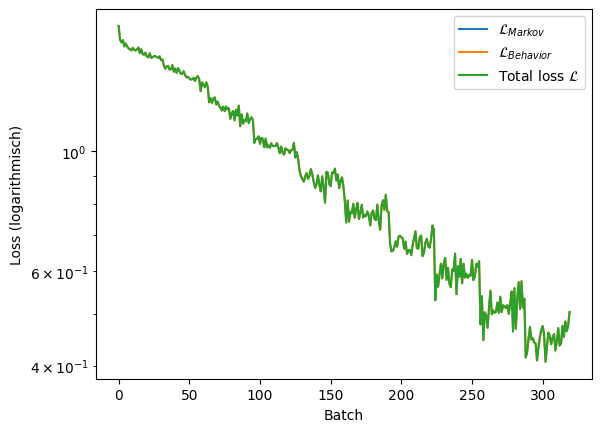

In [2]:
import matplotlib.pyplot as plt
loss_history = np.array(all_losses)      # Form (Anzahl Batches, 3)

loss_names = [
    r"$\mathcal{L}_{Markov}$",
    r"$\mathcal{L}_{Behavior}$",
    r"Total loss $\mathcal{L}$",
]

plt.figure()
for column_number, loss_name in enumerate(loss_names):
    plt.semilogy(loss_history[:, column_number], label=loss_name)
plt.xlabel("Batch")
plt.ylabel("Loss (logarithmisch)")
plt.legend()
plt.show()